# SVM on TF-IDF

This notebook trains a support vector machine (SVM) on the same TF-IDF features and train/test split as the Logistic Regression baseline. With an RBF kernel, the SVM separates the classes with a curved boundary that can't be read directly, so we explain it with post-hoc methods.

The steps: global importance (grouped PFI, KernelSHAP) → feature effects (ALE) → heterogeneity (ICE, centered ICE) → individual decisions (SP-LIME, LIME, SHAP). Grouped PFI and ALE are used instead of plain PFI and PDP because several top terms are correlated (Section 8).

## 1. Setup

In [ ]:
import os, sys
if not os.path.exists("preprocessing.py"):                             
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))  
sys.path.insert(0, os.getcwd())             

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score, roc_auc_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,BREAKING: GOP Chairman Grassley Has Had Enough...,"Donald Trump s White House is in chaos, and th...",fake,1
1,Failed GOP Candidates Remembered In Hilarious ...,Now that Donald Trump is the presumptive GOP n...,fake,1
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,Mike Pence is a huge homophobe. He supports ex...,fake,1
3,California AG pledges to defend birth control ...,California Attorney General Xavier Becerra sai...,real,0
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,fake,1


## 3. Text Preprocessing (NLP Pipeline)

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,BREAKING: GOP Chairman Grassley Has Had Enough...,breaking gop chairman grassley enough demand t...
1,Failed GOP Candidates Remembered In Hilarious ...,failed gop candidate remembered hilarious mock...
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,mike penny new dc neighbor hilariously trollin...
3,California AG pledges to defend birth control ...,california ag pledge defend birth control insu...
4,AZ RANCHERS Living On US-Mexico Border Destroy...,az rancher living u mexico border destroy nanc...


Quick sanity check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 BREAKING: GOP Chairman Grassley Has Had Enough, DEMANDS Trump Jr. Testimony Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of this. To them, it s  fake 

PROCESSED:
 breaking gop chairman grassley enough demand trump jr testimony donald trump white house chaos trying cover russia problem mounting hour refuse acknowledge problem surrounding fake news hoax however fact bear thing differently seems crack congressional public leadership chuck grassley r iowa head se


## 4. TF-IDF Vectorization


In [5]:
X, y, tfidf = get_tfidf_features(df)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (38633, 5000)


Same TF-IDF settings as the baseline (see its Section 4). This cell only shows the size of the matrix; the TF-IDF the model uses is fitted again in the next step, on the training articles only.

## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (30906, 5000)
Test shape: (7727, 5000)

Train class balance:
 label_encoded
0    0.549
1    0.451
Name: proportion, dtype: float64

Test class balance:
 label_encoded
0    0.548
1    0.452
Name: proportion, dtype: float64


### 5.1 Dense Arrays for the Explanations

The SVM itself is trained on the sparse TF-IDF matrix. With 5,000 terms, about 97% of the values are zero, and the sparse version lets the SVM skip them, which makes training much faster. The explanation methods below change individual values and need regular arrays, so dense copies are made here. A model trained on sparse input converts dense input automatically, so both versions give exactly the same predictions.

In [7]:
X_train_dense = X_train.toarray().astype(np.float32)
X_test_dense = X_test.toarray().astype(np.float32)

## 6. Train SVM

We use an SVM with an RBF kernel, which separates fake and real articles with a curved boundary. Instead of a probability, the SVM gives each article a decision value: positive means fake, negative means real. Calibrated probabilities would make training about five times slower, so we use the decision value directly. For LIME, we pass it through a sigmoid to get a score between 0 and 1 that ranks articles in the same order but is not a true probability.

In [8]:
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)
svm_model.fit(X_train, y_train)                # sparse TF-IDF: much faster than dense with 5,000 terms

scores_test = svm_model.decision_function(X_test_dense)   # positive = fake, negative = real
y_pred = (scores_test > 0).astype(int)

## 7. Validate Predictive Performance

In [9]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

rng_tr = np.random.RandomState(RANDOM_STATE)
tr_idx = rng_tr.choice(len(y_train), size=2000, replace=False)
train_pred = (svm_model.decision_function(X_train_dense[tr_idx]) > 0).astype(int)

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train.iloc[tr_idx], train_pred, pos_label=1)
auc = roc_auc_score(y_test, scores_test)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train, 2,000-article sample): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"ROC AUC (test): {auc:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")
print(f"Support vectors: {svm_model.n_support_.sum()} of {len(y_train)} training articles")

              precision    recall  f1-score   support

        real       0.98      0.99      0.99      4238
        fake       0.99      0.98      0.98      3489

    accuracy                           0.98      7727
   macro avg       0.98      0.98      0.98      7727
weighted avg       0.98      0.98      0.98      7727

Fake-class recall (test):  0.9751
Fake-class recall (train, 2,000-article sample): 0.9978   <- large gap vs test = overfitting
Accuracy (test): 0.9837
ROC AUC (test): 0.9984
Share of test articles predicted fake: 0.445
Support vectors: 7865 of 30906 training articles


The SVM catches 97.5% of fake articles (recall = 0.9751) with an accuracy of 98.4% and a ROC AUC of 0.998. That's the best of any model so far, slightly ahead of the baseline logistic regression (recall 0.969, accuracy 0.980). It calls 44.5% of test articles fake, close to the real share of 45.2%.

Training recall (on a 2,000-article sample) is 0.998 against 0.975 on test, so the SVM fits its training data a bit more closely than new data, but the gap is small. 7,865 of the 30,906 training articles (25%) are support vectors: the boundary rests on about a quarter of the articles, the ones closest to it.

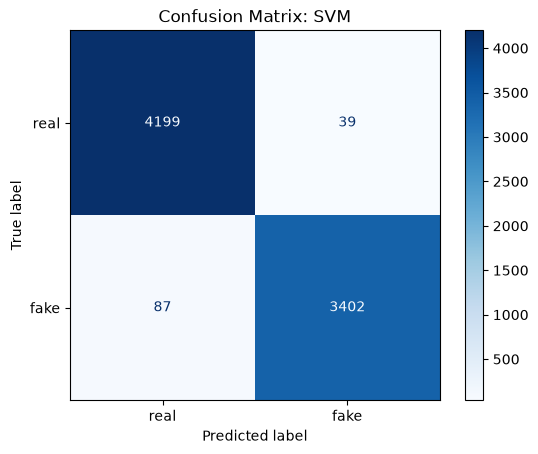

In [10]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: SVM")
plt.show()

- True Positive, correctly caught fake article: 3,402
- False Negative, fake article predicted as real: 87
- False Positive, real article predicted as fake: 39
- True Negative, correctly identified real article: 4,199

98.9% of its "fake" flags are right (precision = 0.989). It misses the fewest fakes of any model: 87, against 108 for the baseline and about 120 for LightGBM and XGBoost. Its false alarms (39) are between the baseline's (44) and the boosted models' (about 34). For a reviewer whose main worry is fakes slipping through, this is the strongest model.

## 8. Top-K Terms and Multicollinearity Check

With 5,000 terms, looking at every term isn't practical: ALE and ICE would need thousands of plots, and a 5,000 × 5,000 correlation matrix can't be read. So we focus on the 30 terms most linked to the label (K = 30), ranked by chi-squared on the training data only.

Chi-squared measures how unevenly a term's weight is split between fake and real articles. Higher means a stronger link to the label, but it doesn't show the direction. We use it because it doesn't depend on any model, so every notebook shares the same list. TF-IDF weights aren't counts, so the scores are only used for ranking, not as significance tests.

In [11]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,video,429.735134
1,said,354.357520
2,image,351.657391
3,via,273.043116
4,featured,245.148761
5,com,236.464647
6,hillary,229.692337


The top seven are video, said, image, via, featured, com and hillary, the same list as in the other notebooks since chi-squared doesn't depend on the model. Four of them (image, via, featured, com) are fingerprints from photo credits and links on fake sites. said is Reuters' writing style, video points to embedded videos, and hillary is the partisan naming fake sites use.

All 30 terms are used below, but tables and plots show only 7 at a time, since people can hold about 7 ± 2 items in working memory.

In [12]:
rng = np.random.RandomState(RANDOM_STATE)

# The SVM is slow to score, so PFI uses 1,000 test articles and PDP/ICE use 200
pfi_idx = rng.choice(X_test_dense.shape[0], size=1000, replace=False)
X_pfi, y_pfi = X_test_dense[pfi_idx].copy(), y_test.iloc[pfi_idx]

pdp_rows = rng.choice(X_test_dense.shape[0], size=200, replace=False)
X_sample = X_test_dense[pdp_rows]

The heatmap below shows how strongly the weights of each pair of top terms move together, from −1 (one goes up when the other goes down) to 1 (they go up together). If some terms move together, methods that treat each word on its own can give misleading results, so this decides which explanation methods we can use.

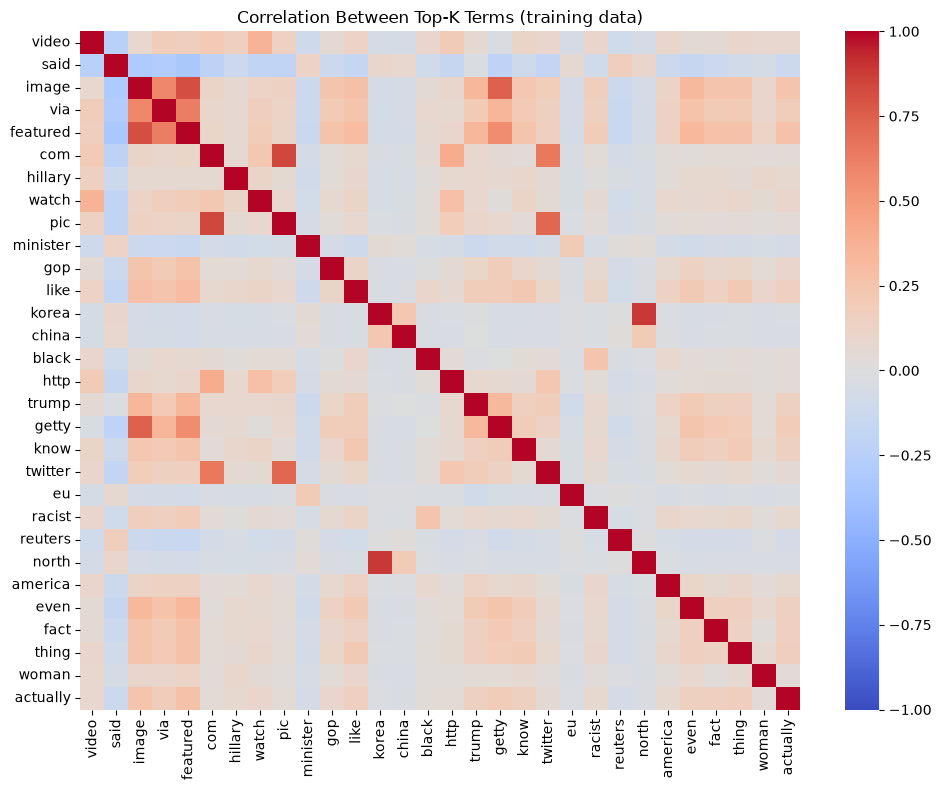

Pairs with |correlation| > 0.5:
korea     north       0.885267
com       pic         0.842176
image     featured    0.814060
          getty       0.743669
pic       twitter     0.721554
com       twitter     0.649922
via       featured    0.628802
image     via         0.579483
featured  getty       0.562061
dtype: float64


In [13]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

Most cells are close to 0, but nine pairs go above 0.5, and they form three groups:

- **Photo credits:** image, featured, getty and via (0.56 to 0.81), all from "Featured image via Getty Images."
- **Links:** com, pic and twitter (0.65 to 0.84), from embedded tweets ("pic.twitter.com").
- **A name:** north and korea (0.89).

These words come as a package: an article that has one of them usually has the others. This rules out two explanation methods that assume the words are independent, plain PFI and PDP. We use grouped PFI (9.1) and ALE (10) instead, and ICE only uses terms outside these groups (11). Each section explains why. The check only covers the top 30 terms and linear relationships, so other dependencies may still exist.

## 9. Global Importance (PFI and KernelSHAP)

### 9.1 Grouped Permutation Feature Importance (PFI)

PFI shuffles a term's values across the test articles and measures how much Fake-class recall drops. A big drop means the model relies on that term to catch fakes. The SVM is slow to score, so PFI uses a random sample of 1,000 test articles and 3 shuffles per unit. Its starting recall (0.974) is therefore slightly different from the full test set.

**Why grouped and not plain PFI:** plain PFI shuffles one term at a time. If we shuffle only via, the article still has image, featured and getty, so the model can still spot the photo credit and barely notices. Each term then looks unimportant, even though the photo credit as a whole might matter a lot. Grouped PFI shuffles correlated terms together, with the same row order, so the whole group is removed at once. Terms that aren't correlated with anything are still shuffled on their own, so for them it's the same as plain PFI.

That turns the 30 top terms into 24 units: three groups (image, via, featured, getty; com, pic, twitter; korea, north) and 21 single terms.

In [14]:
def permutation_recall_drop(model, X_dense, y_true, groups, n_repeats=3, seed=RANDOM_STATE):
    """Shuffle each group of terms TOGETHER (same row order). A group is either a single term
    or a set of correlated terms, so correlated terms cannot stand in for each other."""
    rng = np.random.RandomState(seed)

    def recall_now():
        return recall_score(y_true, (model.decision_function(X_dense) > 0).astype(int), pos_label=1)

    base = recall_now()
    rows = []
    for terms in groups:
        cols = [tfidf.vocabulary_[t] for t in terms]
        original = X_dense[:, cols].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, cols] = original[rng.permutation(len(original))]
            drops.append(base - recall_now())
        X_dense[:, cols] = original
        rows.append((", ".join(terms), np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

# Merge the correlated pairs from Section 8 into groups (image-featured + image-getty -> one group)
term_groups = []
for a, b in high_pairs.index:
    linked = [g for g in term_groups if a in g or b in g]
    merged = {a, b}.union(*linked)
    term_groups = [g for g in term_groups if g not in linked] + [merged]

# Each correlated group is shuffled as one unit; every other top term on its own
pfi_groups = []
for t in top_terms:
    group = next((g for g in term_groups if t in g), {t})
    terms = [u for u in top_terms if u in group]          # keep chi-squared order
    if terms not in pfi_groups:
        pfi_groups.append(terms)

print(f"{len(top_terms)} top terms -> {len(pfi_groups)} PFI units")
base_recall, pfi_df = permutation_recall_drop(svm_model, X_pfi, y_pfi, pfi_groups)
print(f"Recall before shuffling (1,000-article sample): {base_recall:.4f}")
pfi_df.head(7)

30 top terms -> 24 PFI units
Recall before shuffling (1,000-article sample): 0.9740


,term,mean_recall_drop,std
1,said,0.005061,0.007158
7,gop,0.002892,0.001023
17,reuters,0.002892,0.001023
2,"image, via, featured, getty",0.000723,0.002045
15,eu,0.000723,0.001023
4,hillary,0.000723,0.001023
6,minister,0.000000,0.000000


Almost nothing matters on its own. The sample has about 460 fake articles, so one article caught or missed changes recall by about 0.002. said has the largest drop (0.005, about 2 articles), but its standard deviation (0.007) is bigger than the drop itself, so it's noise. gop and reuters cost about 1 article each. The photo-credit group, the top unit for LightGBM and XGBoost, costs almost nothing here (0.0007, less than one article).

So unlike the boosted models, the SVM doesn't depend on any single word or group. Its decisions add up small pushes from thousands of terms, and most articles are far enough from the boundary that removing one signal doesn't flip them.

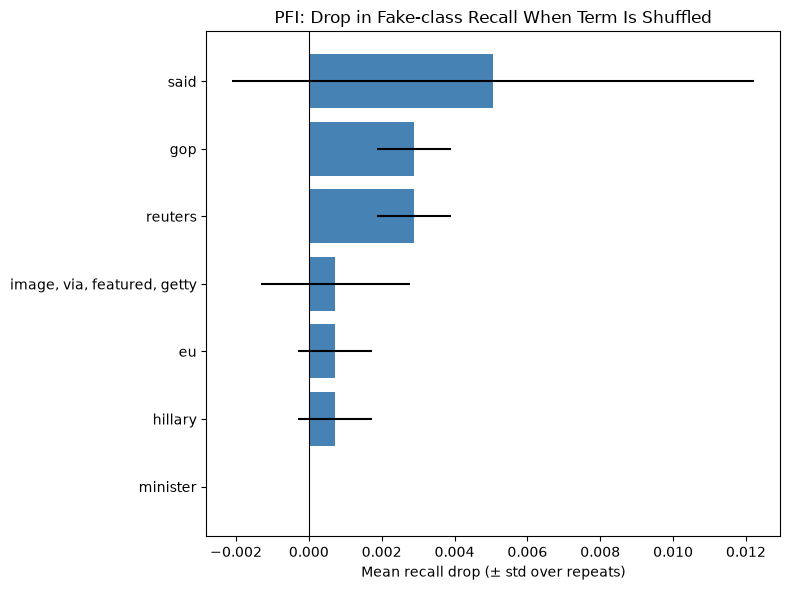

In [15]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

All the bars are tiny, and the error bars of said, the photo-credit group, eu and hillary all reach zero. Only gop and reuters stay just above zero, at about one article each. The check below compares these drops with random terms.

#### Is PFI measuring anything?

As a check, we shuffle 30 random terms from outside the top 30. If their drops are as large as those of the top terms, the PFI ranking cannot be told apart from noise.

In [16]:
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)

# takes about 8 minutes
_, pfi_null = permutation_recall_drop(svm_model, X_pfi, y_pfi, [[feature_names[i]] for i in other_idx])
print(pfi_null["mean_recall_drop"].describe())

count    30.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: mean_recall_drop, dtype: float64


All 30 random terms have a drop of exactly zero: shuffling them never flips a single prediction in the sample. The top units do only slightly better (at most about 2 articles), so for the SVM, PFI shows that no single unit of the top 30 drives its decisions, including the photo credit.

### 9.2 KernelSHAP (global view)

SHAP splits a prediction into a contribution from each term. TreeSHAP only works for tree models and LinearSHAP only for linear ones, so for the RBF SVM we use KernelSHAP, which works with any model.

KernelSHAP treats the model as a black box. For one article, it makes many versions with different combinations of terms switched off, runs the model on each, and fits a weighted linear model to the results. The fitted coefficients estimate each term's Shapley value: its average contribution across all combinations of the other terms. Because it samples combinations rather than trying them all, the values are estimates, and they need many model calls per article.

This is slow for the SVM, and over all 5,000 terms the estimates would be unstable, so we only compute it for the 30 top terms. "Switched off" means the word is absent (weight 0), while all other terms keep the article's own values. So the starting value is the article's decision value with its top 30 terms removed, not the model's average. Values are in decision-value units (positive pushes toward fake) and are computed for 100 test articles.

In [17]:
def kernel_shap_topk(model, x_row, top_idx, nsamples=500):
    # Shapley values for the top-K terms of ONE article; all other terms keep the article's own values
    def f(Z):
        full = np.tile(x_row, (Z.shape[0], 1))
        full[:, top_idx] = Z
        return model.decision_function(full)
    explainer = shap.KernelExplainer(f, np.zeros((1, len(top_idx)), dtype=np.float32))
    values = explainer.shap_values(x_row[top_idx].reshape(1, -1), nsamples=nsamples, silent=True)[0]
    return values, float(explainer.expected_value)

X_shap = X_sample[:100]

# takes about 5 minutes
results = [kernel_shap_topk(svm_model, X_shap[i], top_idx) for i in range(len(X_shap))]
sv_topk = np.array([r[0] for r in results])
base_values = np.array([r[1] for r in results])
print("SHAP values shape:", sv_topk.shape)

SHAP values shape: (100, 30)


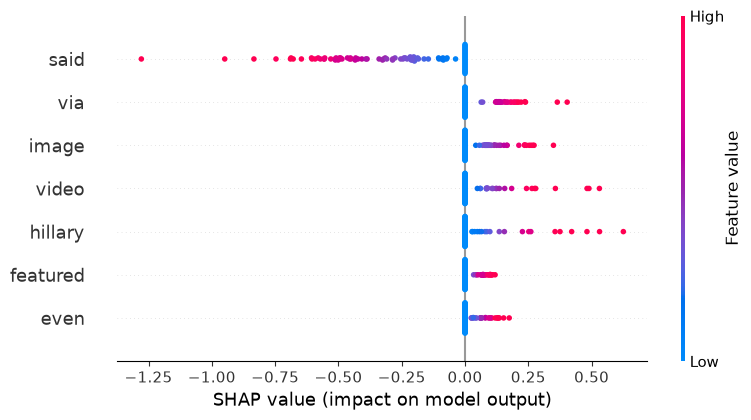

In [18]:
shap.summary_plot(sv_topk, X_shap[:, top_idx], feature_names=list(top_terms), max_display=7)

In [19]:
shap_importance = pd.DataFrame({
    "term": top_terms,
    "mean_abs_shap": np.abs(sv_topk).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
1,said,0.274637
3,via,0.050747
2,image,0.045925
0,video,0.044610
6,hillary,0.043487
4,featured,0.020759
25,even,0.020734


Each dot is one article: its position shows how much a term moved the decision value toward fake (right) or real (left), and its color shows the term's weight (red high, blue low or absent).

Every blue dot is exactly 0: if a word is absent, switching it off changes nothing. said dominates by far. Its average effect (0.27) is more than five times that of any other term, and articles that use it a lot are pushed toward real by up to 1.3. via, image, video and hillary push toward fake by about 0.1 to 0.6 when present, and featured and even by less.

This looks different from PFI, where nothing mattered, but the two answer different questions. SHAP shows that these words do move the SVM's score. PFI shows that removing them rarely moves an article across the boundary, because most articles have plenty of other words pointing the same way.

## 10. Feature Effects (ALE)

ALE shows how the SVM's decision value changes as one term's weight goes up, so it shows the direction and size of each term's effect. It uses the same 1,000-article sample as PFI.

**Why ALE and not PDP:** PDP sets a term to each value in every article while leaving the rest of the article alone. For correlated terms that creates articles that can't exist, such as a photo credit with "image" but no "featured" or "getty", and the curve then describes those fake articles instead of real ones. ALE avoids this. It cuts the term's weights into small intervals and, in each interval, only uses the articles whose weight is actually in that interval. It measures how the prediction changes across that small step, then adds the steps up. 0 on the y-axis means the average decision value.

We plot the six top chi-squared terms: video, said, image, via, featured and com.

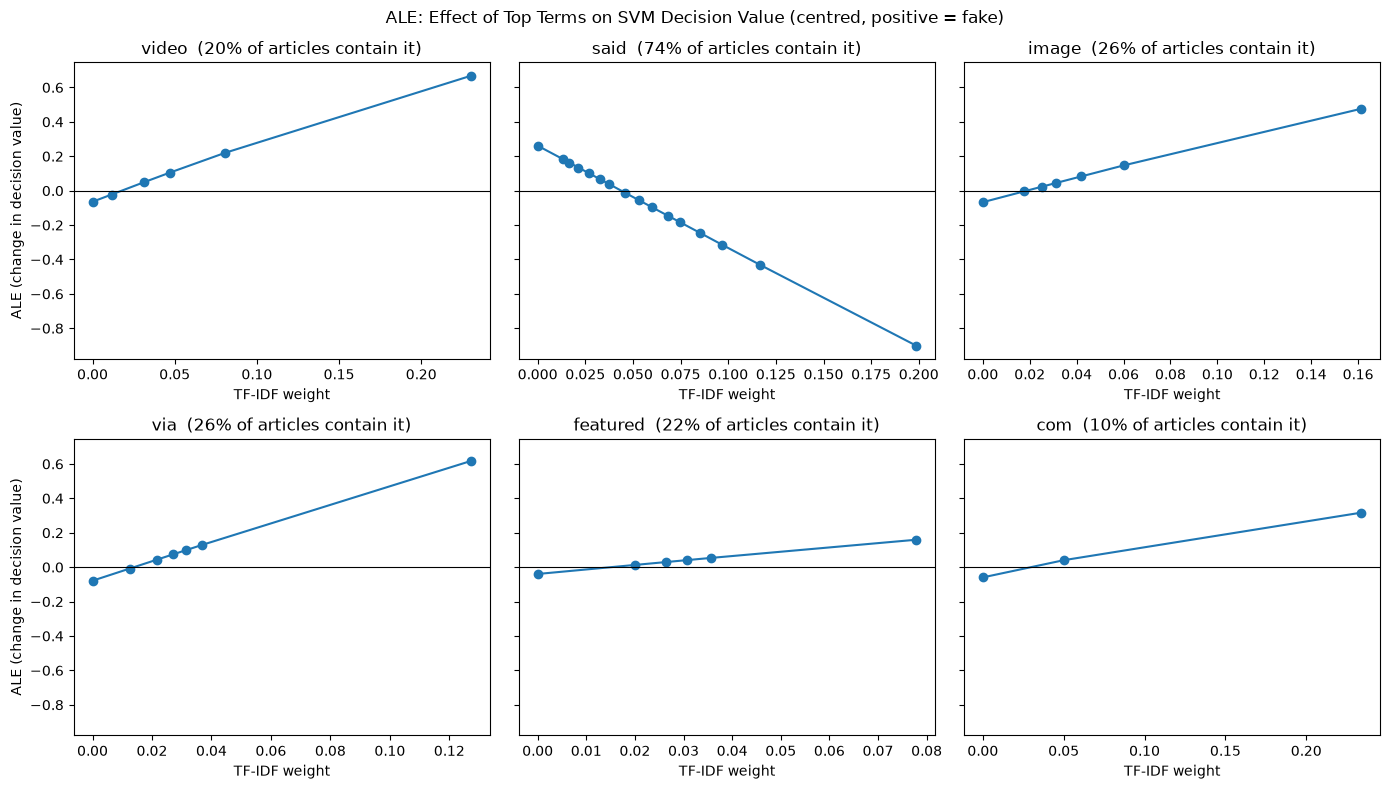

In [20]:
def ale_1d(predict, X, col, n_bins=20):
    """First-order ALE for one column. Bins are quantiles of the column, so most of the
    mass at weight 0 collapses into one edge. Returns bin edges and centred ALE values."""
    x = X[:, col]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 2:
        return edges, np.zeros(len(edges))
    # article in interval (edges[k-1], edges[k]] -> bin k; articles exactly at the lowest edge go to bin 1
    bin_idx = np.clip(np.searchsorted(edges, x, side="left"), 1, len(edges) - 1)
    effects = np.zeros(len(edges) - 1)
    counts = np.zeros(len(edges) - 1)
    for k in range(1, len(edges)):
        rows = X[bin_idx == k]
        if len(rows) == 0:
            continue
        lo, hi = rows.copy(), rows.copy()
        lo[:, col], hi[:, col] = edges[k - 1], edges[k]
        effects[k - 1] = (predict(hi) - predict(lo)).mean()   # local effect, using only articles in this bin
        counts[k - 1] = len(rows)
    ale = np.concatenate([[0.0], np.cumsum(effects)])         # accumulate the local effects
    mids = (ale[:-1] + ale[1:]) / 2
    ale -= (mids * counts).sum() / counts.sum()               # centre so the average effect is 0
    return edges, ale

# The SVM is slow to score, so ALE uses the same 1,000-article sample as PFI, in decision-value units
ale_terms = list(top_terms[:6])
predict_decision = lambda X: svm_model.decision_function(X)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for ax, term in zip(axes.ravel(), ale_terms):
    col = tfidf.vocabulary_[term]
    edges, ale = ale_1d(predict_decision, X_pfi, col)
    ax.plot(edges, ale, marker="o")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{term}  ({(X_pfi[:, col] > 0).mean():.0%} of articles contain it)")
    ax.set_xlabel("TF-IDF weight")
for ax in axes[:, 0]:
    ax.set_ylabel("ALE (change in decision value)")
fig.suptitle("ALE: Effect of Top Terms on SVM Decision Value (centred, positive = fake)")
plt.tight_layout()
plt.show()

Unlike the tree models, the curves are not steps. Each one is close to a straight line, so the effect keeps growing the more often a word appears. The RBF kernel changes smoothly with each weight, so there's no single cutoff.

said falls steadily, from +0.26 when absent to about −0.9 at its highest weights, the biggest effect of the six. video and via rise to about +0.6 or +0.7 at their highest weights, image to about +0.5, com to about +0.3, and featured to about +0.15. At the weights most articles actually have (around 0.05), each word moves the decision value by roughly 0.1 to 0.25, small next to decision values that mostly lie between −3 and 3.

The directions match SHAP and the other models: video and the fingerprint terms push toward fake, and said toward real.

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, to show whether a term affects every article the same way.

ICE works like PDP, one article at a time, so it has the same problem with correlated terms, and there is no ALE version of it. So ICE only uses the top terms that aren't in any correlated group: video, said, hillary, watch, minister and gop.

ICE terms: ['video', 'said', 'hillary', 'watch', 'minister', 'gop']


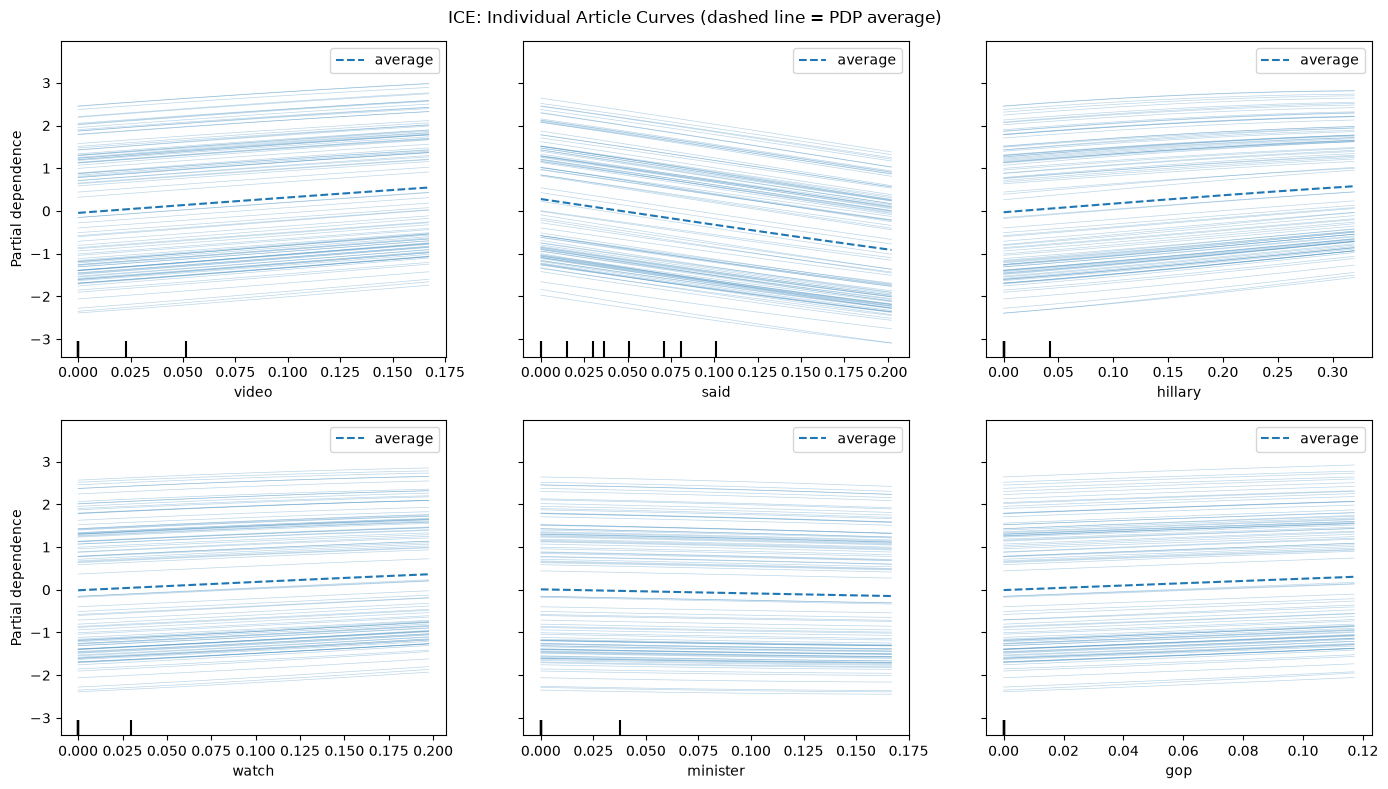

In [21]:
# ICE has no ALE version, so it only uses terms that are not part of any correlated pair
correlated_terms = {t for g in term_groups for t in g}
ice_idx = [i for i in top_idx if feature_names[i] not in correlated_terms][:6]
print("ICE terms:", list(feature_names[ice_idx]))

ice_display = PartialDependenceDisplay.from_estimator(
    svm_model, X_sample,
    features=ice_idx,
    feature_names=list(feature_names),
    kind="both",
    response_method="decision_function",
    subsample=100,
    grid_resolution=10,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

Each thin line is one of 100 articles, and the dashed line is the average. The lines start anywhere from about −2.4 to 2.7, set by the article's other words, and they form two bands: real articles below 0 and fake articles above. The lines are straight and almost parallel, so every article reacts to each term in about the same way. The centered plot below shows this more clearly.

### 11.1 Centered ICE

The ICE plot can be misleading. Each line starts at a different height, set by the article's other words, so a line that starts high and moves a little looks the same as one that starts low and moves a lot. That makes it hard to compare how much the term actually changes each article.

Centered ICE fixes this by shifting every line to start at 0. Each line then shows only the change in decision value when the term is added to that article, so the size of the effect can be compared directly across articles.

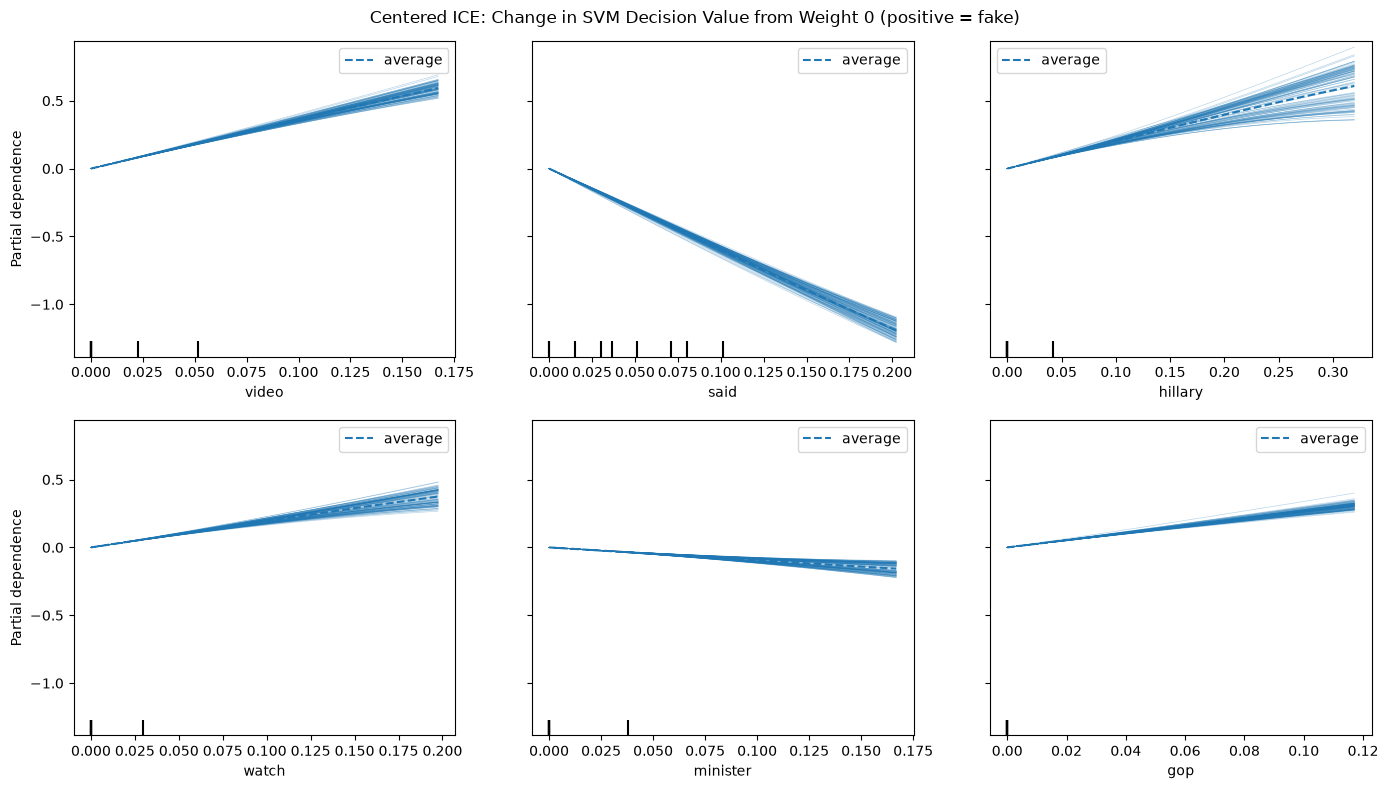

In [22]:
cice_display = PartialDependenceDisplay.from_estimator(
    svm_model, X_sample,
    features=ice_idx,
    feature_names=list(feature_names),
    kind="both",
    centered=True,
    response_method="decision_function",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
cice_display.figure_.set_size_inches(14, 8)
cice_display.figure_.suptitle("Centered ICE: Change in SVM Decision Value from Weight 0 (positive = fake)")
plt.tight_layout()
plt.show()

The lines in each panel are straight and bunched tightly together. Adding video, watch or gop raises every article's decision value by almost the same amount (about +0.6, +0.35 and +0.3 at their highest weights). said lowers every article by about 1.1 to 1.2, and minister by about 0.15. hillary fans out the most, from about +0.35 to +0.85, but still goes the same way for every article.

So the SVM gives each word almost the same push in every article, whatever else the article contains. At these small TF-IDF weights, the RBF kernel behaves almost like a linear model, adding up one small push per word. That's very different from the boosted models, where the same word could move one article by 60 points and another by nothing.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the model overall. Now we look at single articles. First, SP-LIME picks a small set of representative articles. Then we look at three cases chosen by outcome: the fake article the model was most confident about, the fake article it missed most clearly, and the real article it most confidently flagged as fake.

The score shown for each article is the sigmoid of the SVM's decision value. It ranks articles correctly but is not a calibrated probability.

In [23]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    # LIME needs probabilities, so the SVM decision value is passed through a sigmoid
    s = svm_model.decision_function(tfidf.transform(texts).toarray().astype(np.float32))
    p = 1 / (1 + np.exp(-s))
    return np.column_stack([1 - p, p])

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = 1 / (1 + np.exp(-scores_test))      # probability-like score, not calibrated

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

Instead of picking articles by hand, SP-LIME (submodular pick) explains a pool of random test articles and picks the 5 whose explanations together cover the most words with the least repetition. The SVM is slow to score, so the pool is 60 articles. SP-LIME doesn't look at the label or subject, so we check those afterwards.

In [24]:
N_CANDIDATES = 60
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

# takes about 3 minutes
sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=500,
    top_labels=None          # explain the fake class (label 1) for every article
)
sp_idx = cand_idx[sp.V]      # positions of the picked articles in the test set

In [25]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "subject": [df.loc[y_test.index[i], "subject"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "score": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

,subject,true_label,score,outcome
0,News,fake,0.892,"TP (fake, caught)"
1,worldnews,real,0.130,"TN (real, correct)"
2,politics,fake,0.758,"TP (fake, caught)"
3,politicsNews,real,0.163,"TN (real, correct)"
4,politicsNews,real,0.128,"TN (real, correct)"


SP-LIME pick 1 | score = 0.892


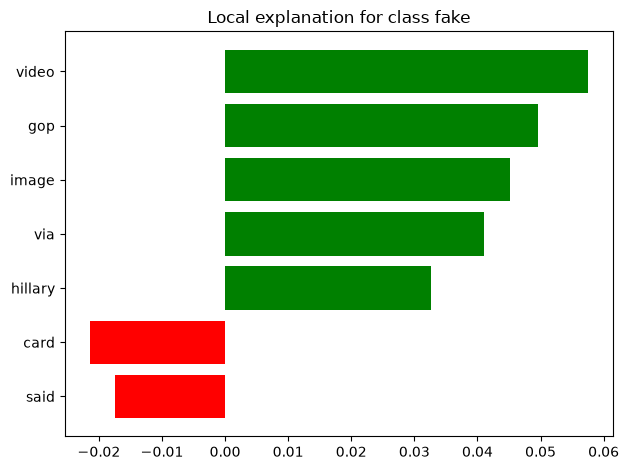

SP-LIME pick 2 | score = 0.130


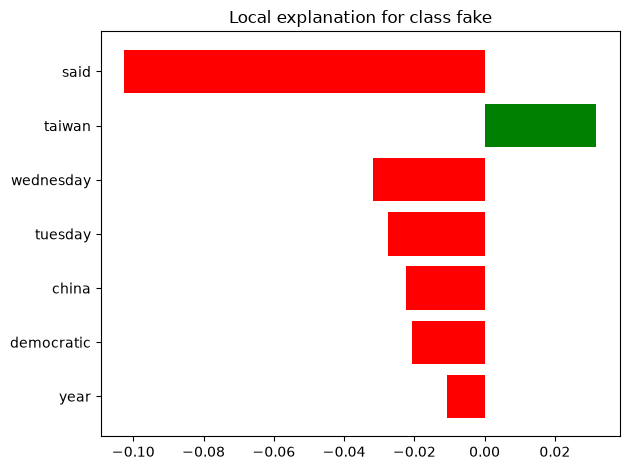

SP-LIME pick 3 | score = 0.758


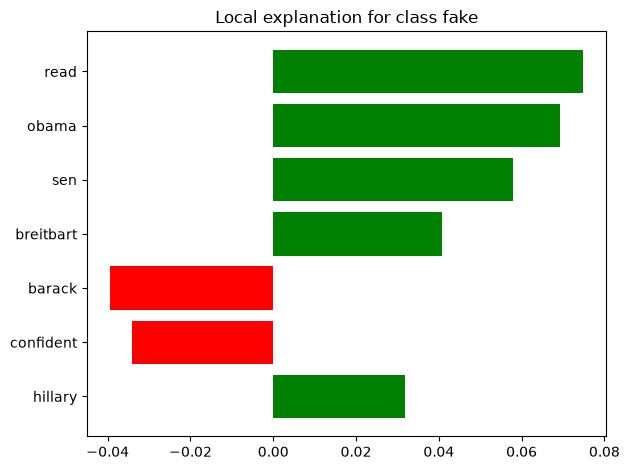

SP-LIME pick 4 | score = 0.163


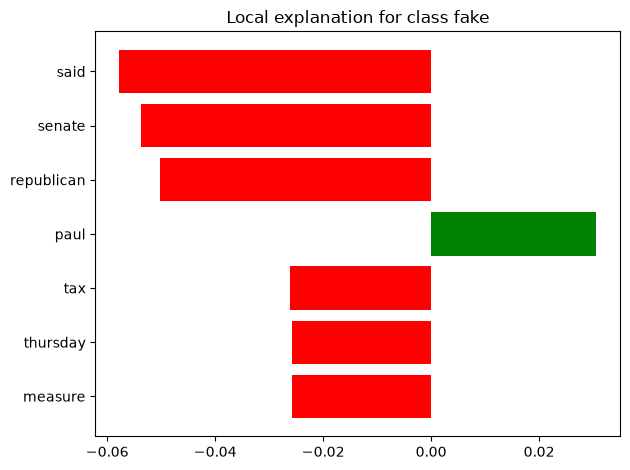

SP-LIME pick 5 | score = 0.128


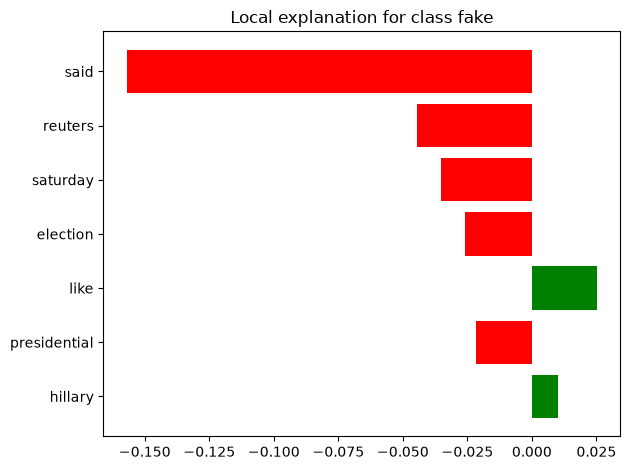

In [26]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | score = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

The picks are two fake articles and three real ones, and the SVM gets all five right. The subject column just mirrors the label (see `dataset_eda.ipynb`). Scores range from 0.13 to 0.89, so it's fairly sure about all five.

**Pick 1 (fake, 0.892).** video, gop, image, via and hillary push toward fake: the photo credit, a video and partisan naming. card and said pull back slightly.

**Pick 2 (real, 0.130).** said (−0.10) leads, with wednesday, tuesday, china and democratic. taiwan pushes toward fake but not enough.

**Pick 3 (fake, 0.758).** read ("READ MORE"), obama, sen and breitbart push toward fake, against barack and confident. This one is caught without a photo credit, on "READ MORE", the abbreviation "sen" and a cited fake-leaning site.

**Pick 4 (real, 0.163).** said, senate, republican, tax and thursday pull toward real, the formal wording of a political news report.

**Pick 5 (real, 0.128).** said (−0.16), reuters, saturday, election and presidential pull toward real.

As with the other models, fakes are caught on fingerprints and partisan words, and real articles on said and Reuters' formal style. The weights are spread over more words than in the tree models, which fits a model that adds up many small pushes.

### 12.2 LIME: Three Cases by Outcome

LIME removes words from one article and watches how the score changes. Positive weights push toward fake, negative toward real.

True Positive (fake, caught) | score = 0.980


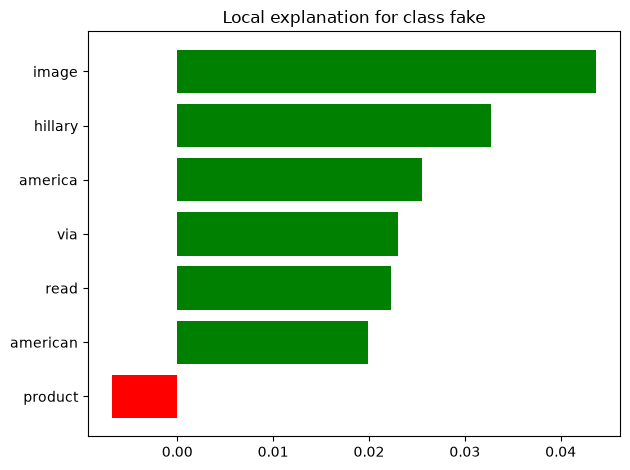

False Negative (fake, missed) | score = 0.151


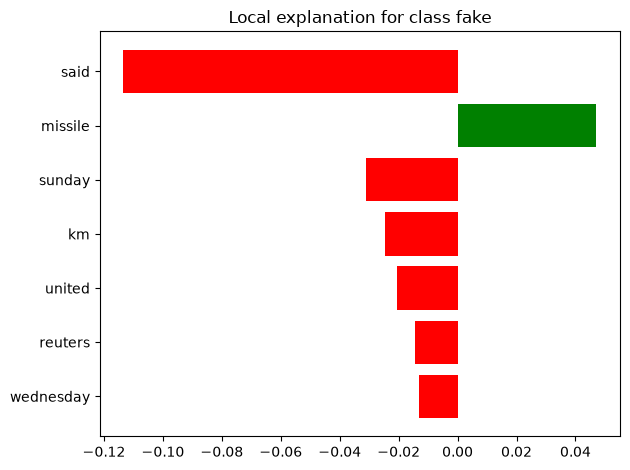

False Positive (real, flagged) | score = 0.830


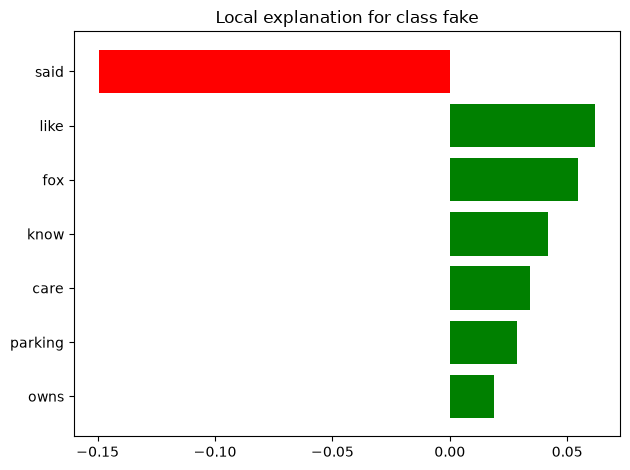

In [27]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=500, labels=(1,)
    )
    print(f"{name} | score = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

To see which articles these are, the cell below prints their headlines. The descriptions that follow refer to them.

In [29]:
for name, i in cases.items():
    print(name, "|", df.loc[y_test.index[i], "title"][:90])

True Positive (fake, caught) | Trump Won’t Tell America Where His Products Are Made, So Here’s A Handy Guide (IMAGES)
False Negative (fake, missed) | N. KOREA’S LATEST MISSILE LAUNCH Aimed At Testing Carrying “Large Scale Heavy Nuclear Warh
False Positive (real, flagged) | Disillusionment, U.S.A. Where voters are just hoping for change.


These are the most extreme articles in each group. The score shown is the sigmoid of the decision value, not a calibrated probability.

**True Positive (score 0.980).** The fake article ("Trump Won't Tell America Where His Products Are Made, So Here's A Handy Guide (IMAGES)") is caught on image, hillary, america, via, read and american (0.02 to 0.04 each), with only product pulling slightly back. That's the photo credit plus partisan words, spread over several terms of similar size.

**False Negative (score 0.151).** The fake article ("N. KOREA'S LATEST MISSILE LAUNCH Aimed At Testing Carrying 'Large Scale Heavy Nuclear Warh…") is the same one the Random Forest missed. Apart from the all-caps headline, it reads like a wire report: said (−0.12), sunday, km, united, reuters and wednesday pull toward real, and only missile pushes toward fake. It reports distances in km, dates events and even mentions Reuters. It's wire-service wording republished on a fake site, and the SVM can't tell it from the real thing.

**False Positive (score 0.830).** This real Reuters article ("Disillusionment, U.S.A. Where voters are just hoping for change.") is a feature piece built on interviews with ordinary voters. Their quotes bring in casual words (like, fox, know, care, parking, owns) that push toward fake and outweigh said (−0.15). A real article that quotes people talking casually gets flagged.

The errors follow the same pattern as the other models: the SVM judges how an article is written, so a wire-style fake gets through and a real article full of everyday speech gets flagged.

LIME uses random samples, so results change a little between runs, especially for the smaller words.

### 12.3 KernelSHAP Waterfall (the missed fake article)

LIME approximates the model around one article, while KernelSHAP splits the model's own output into contributions that add up exactly. Here it explains the missed fake article from 12.2, so the two methods can be compared on the same case. As in 9.2, only the top 30 terms are explained, and the values are in decision-value units.

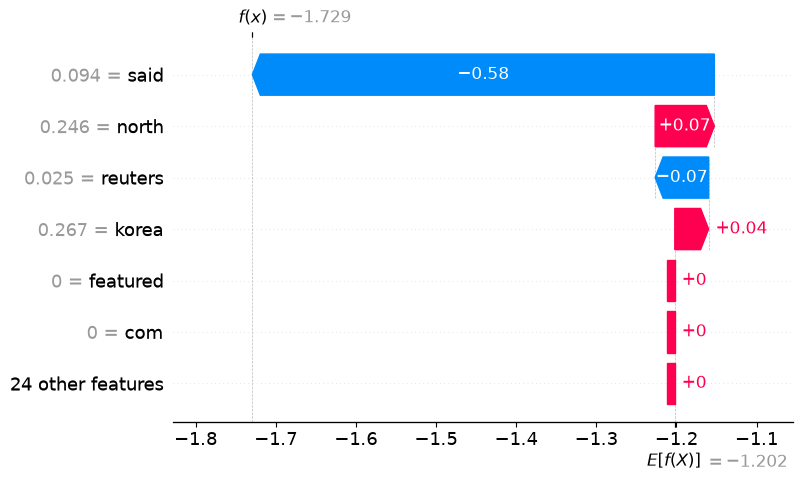

In [28]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx]                      # one row, 1-D

sv_fn, base_fn = kernel_shap_topk(svm_model, x_fn, top_idx)

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn, base_values=base_fn,
        data=x_fn[top_idx], feature_names=list(top_terms)
    ),
    max_display=7
)

The starting value (E[f(X)] = −1.20) is not the model's average. It's this article's decision value with its top 30 terms removed. So before any top term is counted, the article is already well on the real side because of all its other words. The top terms then move it to −1.73 (score 0.151).

said does almost all of it (−0.58). reuters adds −0.07, while north and korea push slightly toward fake (+0.07 and +0.04). The other 26 top terms add nothing, since the article doesn't contain them.

SHAP and LIME agree that said is the main reason for the miss and that reuters points toward real. LIME's other words (sunday, km, missile) aren't in the top 30, so KernelSHAP can't show them. That's the limit of explaining only the top terms: for this article, most of the push toward real comes from words outside the list.

## 13. Summary

The SVM is the best model in the project. It catches 97.5% of fake articles (recall 0.9751), with precision 0.989, accuracy 0.984 and ROC AUC 0.998, ahead of the baseline (0.969 and 0.980) and both boosted models. It misses the fewest fakes (87 vs 108 for the baseline), with slightly fewer false alarms than the baseline (39 vs 44). Training and test recall are close, so it overfits only slightly.

Several top terms come as packages, so we used grouped PFI instead of plain PFI and ALE instead of PDP. The methods show a model that works differently from the tree models:

- **Grouped PFI:** no unit matters on its own. The largest drops are about 2 articles, and removing the whole photo-credit group changes almost nothing, while the same group was the boosted models' top signal.
- **KernelSHAP:** said dominates, and the photo-credit words, video and hillary push toward fake when present. They move the score but rarely flip a decision.
- **ALE:** effects are close to straight lines, so the more often a word appears, the bigger its push. There are no cutoffs as in the trees.
- **ICE:** every article reacts to each word in almost the same way, so the SVM behaves almost like a linear model that adds up one small push per word.
- **LIME:** fakes are caught on fingerprints and partisan words, real articles on said. The worst errors are a wire-style fake about a North Korean missile launch (also missed by the Random Forest) and a real feature piece full of voters' casual quotes.
- **SHAP waterfall:** for the missed fake, said does almost all the work, and most of the push comes from words outside the top 30.

So the SVM is both the most accurate model and the least dependent on any single fingerprint. It still learns the same thing as the others, though: what Reuters articles and these fake sites sound like. Its errors are the same kind: it judges how an article is written, not whether what it says is true.